# Model evaluation: is the default model good enough to use?

The model is trained in `src/train_model.py` (gradient boosting, chosen over logistic regression and the
rule-based segment with rules fixed in advance). This notebook looks at its output in more depth:
calibration, where it beats the existing rule, which defaulters it misses, and how it treats different groups.

Scores in `analytics.customer_risk_score` are **out-of-fold**: each customer was scored by a model that did not
see them during training.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True, "font.size": 10,
})
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
engine = create_engine(URL.create(
    "mssql+pyodbc",
    host=os.getenv("SQL_SERVER", r"localhost\SQLEXPRESS"),
    database=os.getenv("SQL_DATABASE", "CreditRiskDB"),
    query={"driver": "ODBC Driver 18 for SQL Server", "trusted_connection": "yes",
           "TrustServerCertificate": "yes"},
))


def sql(query):
    return pd.read_sql(query, engine)

In [2]:
metrics = json.loads((ROOT / "reports" / "model_metrics.json").read_text())
scores = sql("SELECT * FROM analytics.vw_customer_risk")
for col in ["pd_score", "latest_utilisation", "avg_utilisation_6m"]:
    scores[col] = scores[col].astype(float)
y = scores["default_next_month"]

pd.DataFrame(metrics["test_set"]).T[["auc", "gini", "ks", "average_precision", "capture_top_10pct", "capture_top_20pct"]]

,auc,gini,ks,average_precision,capture_top_10pct,capture_top_20pct
gradient_boosting,0.780,0.560,0.424,0.561,0.316,0.508
logistic_regression,0.758,0.516,0.400,0.526,0.304,0.499
rule_based_segment,0.725,0.449,0.360,0.425,0.268,0.475


On the held-out test set the model reaches Gini 0.56 against 0.45 for the rule-based segment.
The decision rule (boosting must beat logistic regression by 0.01 AUC in CV) was met by a small margin:

In [3]:
pd.Series(metrics["decision"]).drop("features")

boosting_minus_logistic_auc                  0.013
chosen_model                     gradient_boosting
sensitive_attributes_auc_gain               -0.000
sensitive_attributes_used                    False
dtype: object

## 1. Score distribution

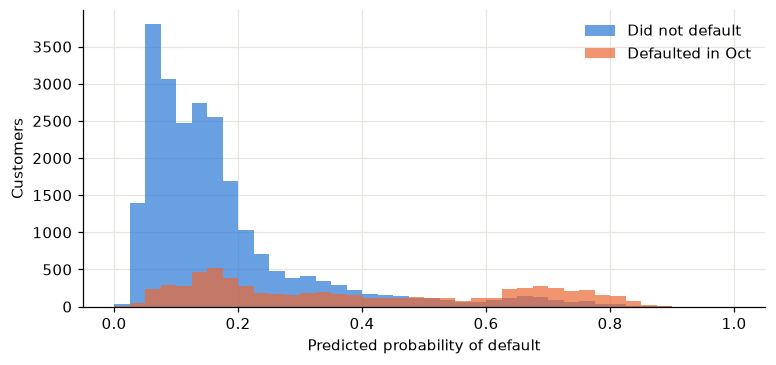

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 1, 41)
ax.hist(scores.loc[y == 0, "pd_score"], bins=bins, color=BLUE, alpha=0.7, label="Did not default")
ax.hist(scores.loc[y == 1, "pd_score"], bins=bins, color=ORANGE, alpha=0.7, label="Defaulted in Oct")
ax.set(xlabel="Predicted probability of default", ylabel="Customers")
ax.legend(frameon=False);

Most non-defaulters sit below 20%. Defaulters are spread out: a clear group above 50%, and a large
group that looks like everyone else. Those are the hard cases (section 4).

## 2. Calibration

If the PD is used as a probability (expected defaults, provisioning, pricing), predicted and actual
rates have to match, not just the ranking.

In [5]:
calib = (scores.groupby("risk_decile")
         .agg(customers=("pd_score", "size"), predicted=("pd_score", "mean"), actual=("default_next_month", "mean")))
calib["gap"] = calib["actual"] - calib["predicted"]
print(f"Expected defaults {scores['pd_score'].sum():,.0f} vs actual {y.sum():,}")
calib

Expected defaults 6,625 vs actual 6,636


,customers,predicted,actual,gap
risk_decile,,,,
1,3000,0.049,0.038,-0.011
2,3000,0.068,0.069,0.000
3,3000,0.088,0.092,0.004
4,3000,0.115,0.101,-0.014
5,3000,0.140,0.150,0.010
6,3000,0.163,0.172,0.009
7,3000,0.194,0.198,0.004
8,3000,0.266,0.252,-0.014
9,3000,0.424,0.435,0.011


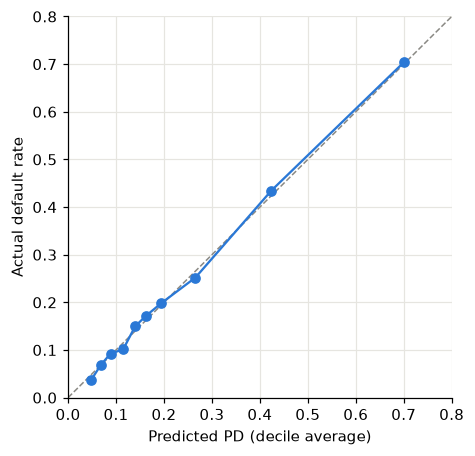

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1)
ax.plot(calib["predicted"], calib["actual"], marker="o", color=BLUE)
ax.set(xlabel="Predicted PD (decile average)", ylabel="Actual default rate", xlim=(0, 0.8), ylim=(0, 0.8));

Every decile is within 1.5 percentage points of the diagonal, so no recalibration step is needed.

## 3. Model vs the existing rule

The rule (`early_warning_segment` in SQL) flags customers as High when they are 2+ months late now or were late
in 3+ of the last 6 months. Where do the two agree?

In [7]:
cross = pd.crosstab(scores["early_warning_segment"], scores["risk_band"])
rate = pd.crosstab(scores["early_warning_segment"], scores["risk_band"], values=y, aggfunc="mean")
display(cross)
rate.style.format("{:.1%}", na_rep="-").background_gradient(cmap="Blues", axis=None)

risk_band,1. Low (<10%),2. Medium (10-25%),3. High (25-50%),4. Very high (50%+)
early_warning_segment,,,,
1. Low,8585,6825,527,5
2. Medium,294,6464,2336,42
3. High,0,22,1382,3518


risk_band,1. Low (<10%),2. Medium (10-25%),3. High (25-50%),4. Very high (50%+)
early_warning_segment,,,,
1. Low,6.4%,14.7%,31.1%,80.0%
2. Medium,10.5%,17.1%,32.4%,64.3%
3. High,-,13.6%,42.8%,68.1%


At the top they mostly agree: the rule's High segment is already very risky, and flagging the same number of
customers both find the same defaulters (`same_flag_volume_as_rule_high` below). The model adds value
**inside** the rule's Low and Medium groups, which the rule treats as uniform. Within the rule's Low group the model
separates customers defaulting at 6.4% (model Low), 14.7% (Medium) and 31.1% (High); within the rule's Medium group
at 10.5%, 17.1% and 32.4%.

In [8]:
pd.Series(metrics["same_flag_volume_as_rule_high"])

flagged_share     0.163
rule_precision    0.603
rule_recall       0.443
model_precision   0.603
model_recall      0.444
dtype: float64

## 4. Which defaulters does the model miss?

Defaulters the model ranks in the bottom half of the portfolio, compared with defaulters it catches in the top 20%.

In [9]:
defaulters = scores[y == 1]
top20 = defaulters["risk_decile"] >= 9
bottom50 = defaulters["risk_decile"] <= 5
compare = pd.DataFrame({
    "caught (top 20%)": defaulters[top20].agg({"months_delinquent_6m": "mean", "latest_utilisation": "mean",
                                               "credit_limit": "median", "avg_payment_ratio_capped": "mean"}),
    "missed (bottom 50%)": defaulters[bottom50].agg({"months_delinquent_6m": "mean", "latest_utilisation": "mean",
                                                     "credit_limit": "median", "avg_payment_ratio_capped": "mean"}),
})
print(f"{bottom50.sum():,} of {len(defaulters):,} defaulters ({bottom50.mean():.0%}) are in the bottom half")
compare

1,350 of 6,636 defaulters (20%) are in the bottom half


,caught (top 20%),missed (bottom 50%)
months_delinquent_6m,3.497,0.053
latest_utilisation,0.564,0.419
credit_limit,70000.000,160000.000
avg_payment_ratio_capped,0.103,0.415


In [10]:
(defaulters[bottom50]["latest_pay_status_label"].value_counts(normalize=True).head(5)
 .to_frame("share of missed defaulters"))

,share of missed defaulters
latest_pay_status_label,
Revolving (minimum paid),0.638
Paid in full,0.219
No consumption,0.123
1 month late,0.020


The missed defaulters look like good customers on paper: never late, revolving or paying in full, normal
utilisation, higher limits. Nothing in six months of statements separates them, so better features would
have to come from outside this dataset (income changes, other products, bureau data).

## 5. Fairness

Sex and marital status are not model inputs (they added no AUC). Leaving them out doesn't guarantee equal
treatment, because other features can act as proxies, so I check the outcomes by group.

In [11]:
def by_group(col):
    return (scores.groupby(col)
            .agg(customers=("pd_score", "size"), actual=("default_next_month", "mean"),
                 predicted=("pd_score", "mean"), flagged_50pct=("pd_score", lambda s: (s >= 0.5).mean())))

display(by_group("sex_label"))
by_group("age_band")

,customers,actual,predicted,flagged_50pct
sex_label,,,,
Female,18112,0.208,0.212,0.109
Male,11888,0.242,0.234,0.135


,customers,actual,predicted,flagged_50pct
age_band,,,,
21-29,9618,0.228,0.229,0.132
30-39,11238,0.203,0.203,0.098
40-49,6464,0.230,0.225,0.121
50-59,2341,0.249,0.252,0.149
60+,339,0.283,0.272,0.192


Predicted rates track actual rates for men and women and across age bands, and flag rates differ only as much
as actual risk does. Age and education are still model inputs; in a real bank I'd review that with model risk.

## Summary

- Gini 0.56 on unseen customers vs 0.45 for the rule; calibrated within 1.5 points per decile.
- Same performance as the rule at the very top, better ranking in the middle of the book, plus a usable probability.
- About a fifth of defaulters show no warning signs in the data; the model can't be expected to find them.
- No sign of unequal treatment by sex or age.